# 06 · Evaluation of the complete recommender (Person 6)

This notebook produces the results of **report section 7**. Sections 3, 4 and 5 evaluated each component separately (label quality, encoders on queries with no word in common, scoring formula on the tuning personas). Here we evaluate the **complete system as the user sees it**: from a filled-in questionnaire to the top 3.

| Notebook section | Report section | Question |
|---|---|---|
| 2. Main evaluation (MiniLM) | 7.1 / 7.7 | Is the top 3 relevant? Are the user's choices respected? |
| 3. Robustness to rephrasing | 7.3 | Does the system depend on meaning or on exact words? |
| 4. Ablation of the formula | 7.4 | Is every term of the formula useful? |
| 5. Sensitivity to the user's weights | 7.5 | Does a higher importance for a block change the ranking as expected? |
| 6. Qualitative analysis | 7.6 | Why does it work, and why does it fail? |
| 7. Encoder comparison | 7.2 | Is SBERT better than lexical and static baselines on the complete system? |
| 8. Blind manual judgments | 7.2 / 7.7 | Are the recommended books relevant, including those we did not list in advance? |

**Method.** All metric code lives in `src/evaluation.py` (unit tests in `tests/test_evaluation.py`). It calls P4's real pipeline (`Recommender.score_table` and `Recommender.diversify`) and never re-implements the scoring, so we measure exactly what the application recommends.

**How to run.** Python 3.11 or 3.12 is recommended. The first run encodes the catalogue with MiniLM (≈ 7 min on CPU, then cached). The GloVe baselines need `gensim`; MPNet takes ≈ 80 min on CPU and is therefore switched off by default (`RUN_MPNET`), it is best run on a GPU (Colab).

## 1. Setup

We load the catalogue (`books_enriched.parquet`, 12,000 books) and the **10 evaluation personas** (`data/eval/personas.json`). Their expected genres, themes and relevant books were fixed by hand **before** running the system, and they are distinct from the 8 tuning personas that P4 used to calibrate the scores.

**Rule on the "book I loved".** A first run showed that each `loved_book` answer described one of the expected books (e.g. *a lonely widower and a noisy new family next door* = *A Man Called Ove*), which favoured lexical methods and, more importantly, rewarded the system for recommending a book the user **has already read**. We therefore fixed a rule from the `loved_book` texts only (without looking at the results): the work it describes is stored in `expected.loved_book_work` and is **never counted as relevant**. We only report how often the system returns it.

In [1]:
# --- Imports -----------------------------------------------------------------
import sys, time, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                     # so that `import src...` works from notebooks/
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.data_loader import load_books
from src.recommender import load_blocks_safe
from src import evaluation as ev

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)
FIG = config.FIGURES_DIR                          # figures saved for the report and the slides
FIG.mkdir(parents=True, exist_ok=True)

# Heavy, optional experiments (section 7)
RUN_MPNET = True                                 # ≈ 80 min on CPU: switch on when running on a GPU
try:
    import gensim  # noqa: F401                   # needed by the GloVe baselines
    RUN_GLOVE = True
except ImportError:
    RUN_GLOVE = False
print("GloVe available:", RUN_GLOVE, "| MPNet enabled:", RUN_MPNET)

GloVe available: True | MPNet enabled: True


In [2]:
# --- Catalogue, taxonomy and evaluation personas ----------------------------
books = load_books()                              # 12,000 books, enriched by P2
blocks = load_blocks_safe()                       # Genre / Themes / Style / Atmosphere labels
personas = ev.load_eval_personas()                # 10 hand-built test personas

overview = pd.DataFrame([{
    "id": p["id"],
    "name": p["name"],
    "audience": p["answers"]["audience"],
    "expected genres": ", ".join(p["expected"]["genres"]),
    "n relevant works": len(p["expected"]["relevant"]),
    "must not appear": len(p["expected"].get("must_not_appear", [])),
    "excluded author": ", ".join(p["expected"].get("excluded_authors", [])) or "-",
    "book already read (not relevant)": p["expected"].get("loved_book_work", {}).get("title", "-"),
} for p in personas])
print(f"{len(books):,} books, {len(personas)} personas")
overview

12,000 books, 10 personas


,id,name,audience,expected genres,n relevant works,must not appear,excluded author,book already read (not relevant)
0,E01_children_fantasy,Children's fantasy adventure,Children,"Fantasy, Children's",2,0,-,The Lightning Thief
1,E02_nordic_noir,Dark Nordic crime thriller,Adult,"Mystery & Detective, Thriller & Suspense",4,0,-,The Girl with the Dragon Tattoo
2,E03_historical_romance,Sweeping historical romance,Adult,"Romance, Historical Fiction",3,0,-,North and South
3,E04_ya_dystopia,Young adult dystopia,Young Adult,"Science Fiction, Young Adult",4,2,-,Uglies
4,E05_psychological_literary,Literary psychological novel,Adult,"Literary Fiction, Classics",4,0,-,Notes from Underground
5,E06_cozy_mystery,Cosy mystery,Adult,Mystery & Detective,4,0,-,The No. 1 Ladies' Detective Agency
6,E07_memoir,Memoir of hardship,Adult,Biography & Memoir,3,0,-,I Know Why the Caged Bird Sings
7,E08_horror_no_king,"Supernatural horror, favourite author excluded",Adult,Horror,6,0,Stephen King,The Shining
8,E09_victorian_classics,19th-century social novel,Adult,"Classics, Literary Fiction",5,0,-,Middlemarch
9,E10_feel_good,Feel-good novel,Adult,"Literary Fiction, Humour",4,0,-,A Man Called Ove


## 2. Main evaluation with the production model (MiniLM)

We build the recommender exactly as the application does: P3's `EmbeddingEngine` with `all-MiniLM-L6-v2`, P4's formula and calibration.

**Sanity check first.** `ev.run_pipeline` runs steps 1–4 of P4's pipeline without building the explanations (which the metrics do not need). We check that it returns **the same top 3** as P4's `recommend()` for every persona; otherwise the evaluation would not measure the real system.

In [20]:
# --- Recommender used by the application (MiniLM) ----------------------------
t0 = time.time()
rec = ev.make_recommender("minilm", books, blocks)
print(f"engine: {rec.engine.model_name} | book matrix {rec.book_emb.shape} | ready in {time.time()-t0:.0f}s")

# --- Sanity check: our evaluation path == the application's recommend() -----
same = []
for p in personas:
    ours = ev.run_pipeline(rec, p["answers"])["top_ids"]
    _, recs = rec.recommend(p["answers"], top_k=3)
    same.append(ours == [r.book_id for r in recs])
print("identical top 3 for all personas:", all(same), f"({sum(same)}/{len(same)})")
assert all(same), "run_pipeline must reproduce recommend() exactly"

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

engine: sentence-transformers/all-MiniLM-L6-v2 | book matrix (12000, 384) | ready in 3s
identical top 3 for all personas: True (10/10)


**Metrics** (definitions in report section 7.1):

- **genre-precision@3**: share of the 3 books carrying at least one expected genre;
- **theme-overlap@3**: share of the expected themes found among the themes of the 3 books;
- **hit@3**: at least one hand-picked relevant book in the top 3;
- **reciprocal rank**: 1 / rank of the first relevant book among the ranked candidates (0 if it was not retrieved); the **MRR** is its mean;
- **constraints_ok**: no excluded author and no "must not appear" book in the top 3;
- **loved_book_in_top3**: the system returns the book the user said they already loved (reported, never counted as relevant);
- **seconds**: time of one recommendation, model already loaded.

Genre and theme metrics rely on P2's labels, which are imperfect: a relevant book with a wrong label counts as a miss. Hit@3 and MRR rely on books chosen by hand and do not have this bias.

In [21]:
# --- One row per persona -----------------------------------------------------
main = ev.evaluate(rec, personas)
ev.save_results(main, "main_minilm")
main[["persona", "genre_precision@3", "theme_overlap@3", "hit@3", "first_relevant_rank",
      "reciprocal_rank", "constraints_ok", "loved_book_in_top3", "seconds", "top3"]]

,persona,genre_precision@3,theme_overlap@3,hit@3,first_relevant_rank,reciprocal_rank,constraints_ok,loved_book_in_top3,seconds,top3
0,E01_children_fantasy,1.000000,0.666667,0.0,NaN,0.000000,True,False,0.093,The Blue Fairy Book | The Witches | The Little Prince
1,E02_nordic_noir,1.000000,1.000000,0.0,14.0,0.071429,True,False,0.043,Night Sin | The Man From Beijing | The One from the Othe...
2,E03_historical_romance,1.000000,1.000000,0.0,NaN,0.000000,True,False,0.052,"Twentieth Wife, the | Mine Till Midnight | Beauty"
3,E04_ya_dystopia,1.000000,1.000000,0.0,41.0,0.024390,True,False,0.049,Rebellion | Unsouled | Alive : Book One of the Generatio...
4,E05_psychological_literary,1.000000,1.000000,0.0,10.0,0.100000,True,False,0.051,False Memory | The Room | The Bad Place
5,E06_cozy_mystery,0.666667,1.000000,0.0,17.0,0.058824,True,False,0.049,"A Study In Scarlet Women | Cold Comfort Farm | Farewell,..."
6,E07_memoir,1.000000,1.000000,0.0,31.0,0.032258,True,False,0.051,Life Among the Savages | The Writing Life | All You Can ...
7,E08_horror_no_king,1.000000,1.000000,0.0,34.0,0.029412,True,False,0.092,Petals on the Wind | The Amityville Horror | The Superna...
8,E09_victorian_classics,1.000000,1.000000,1.0,3.0,0.333333,True,False,0.049,Howards End | Cold Comfort Farm | North and South
9,E10_feel_good,1.000000,1.000000,0.0,NaN,0.000000,True,False,0.048,This Book Will Save Your Life | The Letter : Absolutely ...


In [22]:
# --- Averages over the 10 personas (values for report sections 7.2 and 7.7) --
main_summary = pd.Series(ev.summarize(main), name="MiniLM")
main_summary

genre_precision@3      0.967
theme_overlap@3        0.967
hit@3                    0.1
MRR                    0.065
constraints_ok         10/10
loved_book_returned     0/10
median_seconds          0.05
Name: MiniLM, dtype: object

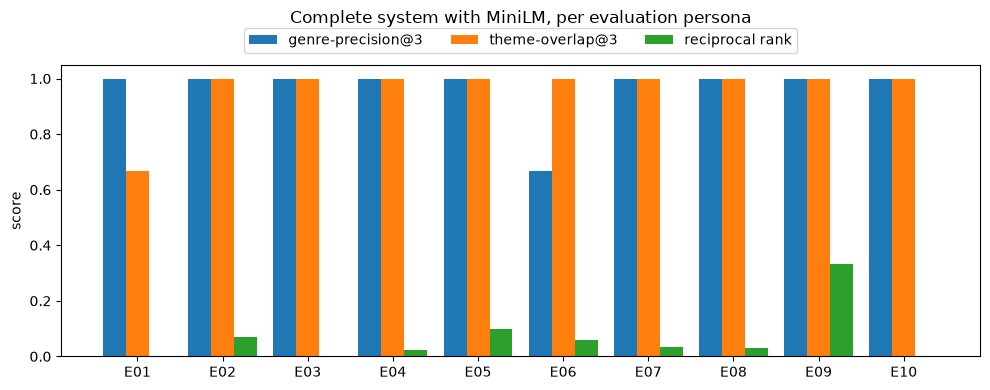

In [23]:
# --- Figure: per-persona view --------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(main))
ax.bar(x - 0.27, main["genre_precision@3"], 0.27, label="genre-precision@3")
ax.bar(x,        main["theme_overlap@3"],   0.27, label="theme-overlap@3")
ax.bar(x + 0.27, main["reciprocal_rank"],   0.27, label="reciprocal rank")
ax.set_xticks(x, [p.split("_", 1)[0] for p in main["persona"]])
ax.set_ylim(0, 1.05); ax.set_ylabel("score"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.15))
ax.set_title("Complete system with MiniLM, per evaluation persona", pad=30)
plt.tight_layout(); plt.savefig(FIG / "06_per_persona.png", dpi=150); plt.show()

## 3. Robustness to rephrasing (report 7.3)

Each persona has three rewritings of its main request with the same meaning and different words. A system that understands **meaning** should return roughly the same top 3. We measure the Jaccard similarity between the original top 3 and the top 3 of each rephrasing (1 = identical, 0 = nothing in common). The lexical baseline is measured in section 7 for comparison.

In [24]:
stab = ev.paraphrase_stability(rec, personas)
ev.save_results(stab, "paraphrase_minilm")
print(f"MiniLM: mean Jaccard = {stab['mean_jaccard'].mean():.3f}, "
      f"{(stab['identical_top3'] == 3).sum()}/{len(stab)} personas keep an identical top 3 for all 3 rephrasings")
stab

MiniLM: mean Jaccard = 0.633, 1/10 personas keep an identical top 3 for all 3 rephrasings


,persona,mean_jaccard,identical_top3,n_paraphrases
0,E01_children_fantasy,0.833333,2,3
1,E02_nordic_noir,0.500000,0,3
2,E03_historical_romance,1.000000,3,3
3,E04_ya_dystopia,0.500000,0,3
4,E05_psychological_literary,0.566667,1,3
5,E06_cozy_mystery,0.300000,0,3
6,E07_memoir,0.400000,0,3
7,E08_horror_no_king,0.833333,2,3
8,E09_victorian_classics,0.833333,2,3
9,E10_feel_good,0.566667,1,3


## 4. Ablation of the formula (report 7.4)

Section 5 defines

$$\text{Final} = \frac{\alpha \tilde S_{desc} + \beta\, \text{Coverage} + \lambda\, \text{Pop}}{\alpha + \beta + \lambda} - \mu \max(0, \cos(q_{avoid}, e_j) - \tau)$$

To justify each term, we remove it and measure the effect on the 10 personas. P4 exposes every constant as a parameter of `score_table`, so the variants run the same code with different values (see `ev.ABLATIONS`). "Without popularity" sets $\lambda = 0$ in the user profile.

In [25]:
abl = ev.ablation(rec, personas)
ev.save_results(abl, "ablation_minilm")
abl

,genre_precision@3,theme_overlap@3,hit@3,MRR,constraints_ok,loved_book_returned,median_seconds
variant,,,,,,,
Blurb only (S_desc),0.800,0.967,0.1,0.123,10/10,0/10,0.043
Coverage only,1.000,0.917,0.2,0.151,10/10,0/10,0.041
Without calibration,1.000,0.917,0.2,0.139,10/10,1/10,0.042
Without 'to avoid' penalty,0.967,0.967,0.0,0.055,10/10,0/10,0.042
Without popularity,0.967,0.917,0.1,0.059,10/10,0/10,0.042
Full formula,0.967,0.967,0.1,0.065,10/10,0/10,0.046


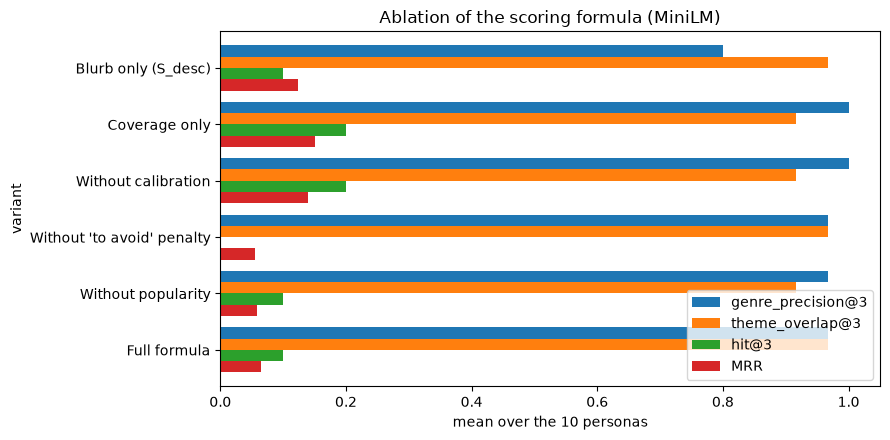

In [26]:
# --- Figure: ablation ----------------------------------------------------------
ax = abl[["genre_precision@3", "theme_overlap@3", "hit@3", "MRR"]].plot.barh(figsize=(9, 4.5), width=0.8)
ax.set_xlim(0, 1.05); ax.set_xlabel("mean over the 10 personas"); ax.invert_yaxis()
ax.set_title("Ablation of the scoring formula (MiniLM)")
plt.tight_layout(); plt.savefig(FIG / "06_ablation.png", dpi=150); plt.show()

## 5. Sensitivity to the user's weights (report 7.5)

The importance Likert answers become the weights $W_b$ of the coverage score. If the system is consistent, raising the importance of **Themes** from 1 to 5 (other answers unchanged) should push up the books that are close to the requested themes, so the mean Themes score of the top 10 should increase.

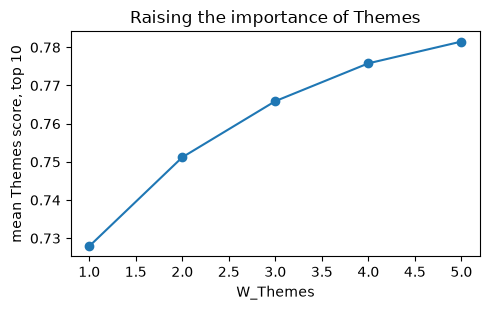

,W_Themes,mean Themes score of top 10
0,1,0.7279
1,2,0.7512
2,3,0.7659
3,4,0.7758
4,5,0.7815


In [27]:
sens = ev.weight_sensitivity(rec, personas, block="Themes")
ev.save_results(sens, "weight_sensitivity_themes")
ax = sens.plot(x="W_Themes", marker="o", legend=False, figsize=(5, 3.2))
ax.set_ylabel("mean Themes score, top 10"); ax.set_title("Raising the importance of Themes")
plt.tight_layout(); plt.savefig(FIG / "06_weight_sensitivity.png", dpi=150); plt.show()
sens

## 6. Qualitative analysis (report 7.6)

Numbers do not say *why* a recommendation is good or bad. We look at the full output of the application (`recommend()`: score, matched labels, closest sentence of the blurb, template explanation) for the **3 best** and the **2 worst** personas, ranked by reciprocal rank then genre-precision.

In [28]:
ranked = main.sort_values(["reciprocal_rank", "genre_precision@3"], ascending=False)
best, worst = ranked.head(3)["persona"].tolist(), ranked.tail(2)["persona"].tolist()
by_id = {p["id"]: p for p in personas}

def show(pid):
    # Print what the user would see for one persona, plus what we expected.
    p = by_id[pid]
    _, recs = rec.recommend(p["answers"], top_k=3)
    print(f"=== {pid} — {p['name']}")
    print("request :", p["answers"]["free_text"]["ideal_book"])
    print("expected:", "; ".join(w["title"] for w in p["expected"]["relevant"]))
    for r in recs:
        print(f"  {r.rank}. {r.title} ({r.authors}) — {r.final_score:.2f} {r.match_label}")
        print(f"     closest sentence ({r.best_sentence_score:.2f}): {r.best_sentence[:160]}")
        print(f"     genres: {', '.join(books.at[books.index[books.book_id == r.book_id][0], 'genres'])}")
    print()

print("##### BEST\n"); [show(pid) for pid in best]
print("##### WORST\n"); [show(pid) for pid in worst];

##### BEST

=== E09_victorian_classics — 19th-century social novel
request : A long, rich nineteenth-century English novel about provincial society, social class and money, with many characters whose fates slowly intertwine.
expected: Bleak House; North and South; Cranford; Far from the Madding Crowd; Vanity Fair
  1. Howards End (E M Forster) — 0.86 Excellent
     closest sentence (0.55): What makes this masterpiece a pure delight for contemporary readers is its vibrant portrait of life in Edwardian England, and the wonderful characters who inhab
     genres: Literary Fiction, Classics, Poetry & Drama
  2. Cold Comfort Farm (Stella Gibbons) — 0.80 Excellent
     closest sentence (0.52): In Gibbons's classic tale, a resourceful young heroine finds herself in the gloomy, overwrought world of a Hardy or Bronte novel and proceeds to organize everyo
     genres: Literary Fiction, Classics
  3. North and South (Alan Shelston, Elizabeth Gaskell) — 0.79 Excellent
     closest sentence (0.57):

In [29]:
# --- Full template explanation of one recommendation (what the app displays) --
_, recs = rec.recommend(by_id[best[0]]["answers"], top_k=1)
print(recs[0].title, "\n")
print(recs[0].explanation)

Howards End 

This book is an excellent match for what you described. Its synopsis is semantically close to your description (similarity 0.53), especially: «What makes this masterpiece a pure delight for contemporary readers is its vibrant portrait of life in Edwardian England, and the wonderful characters who inhabit the charming old country house in Hertfordshire called…». Its style (Dense literary prose (0.98)) fits the kind of writing you asked for. Atmosphere match: 18th-19th century (1.00). Genre match: Literary Fiction (1.00), Classics (1.00). It shares the themes you care about: Family relationships (0.92), Love & heartbreak (0.87). What weighs most in its score: how close its synopsis is to your description. Overall preference coverage: 86%.


## 7. Encoder comparison on the complete system (report 7.2)

Section 4 compared the encoders on retrieval only. Here each encoder is plugged into the **same complete pipeline** (same formula, same filters); each has its own embedding cache and its own calibration (computed on P4's tuning personas, never on the test personas).

The pipeline needs dense vectors, so the lexical baseline is **TF-IDF + LSA** (`tfidf-lsa`, truncated SVD, 256 dimensions). LSA captures part of the synonymy, so it is a slightly stronger baseline than pure keyword matching (pure TF-IDF is in section 4.7).

In [30]:
encoders = ["tfidf-lsa"] + (["glove-tfidf"] if RUN_GLOVE else []) + ["minilm"] + (["mpnet"] if RUN_MPNET else [])
print("encoders compared:", encoders)

rows, recs_by_encoder, tops = [], {"minilm": rec}, {}
for name in encoders:
    t0 = time.time()
    r = recs_by_encoder.get(name) or ev.make_recommender(name, books, blocks)   # MiniLM already built
    recs_by_encoder[name] = r
    setup = time.time() - t0
    df = ev.evaluate(r, personas)
    st = ev.paraphrase_stability(r, personas)
    ev.save_results(df, f"main_{name}")
    tops[name] = ev.tops_by_persona(df)          # top 3 of each persona, for the judgments (section 8)
    rows.append({"encoder": name, **ev.summarize(df),
                 "paraphrase_jaccard": round(st["mean_jaccard"].mean(), 3),
                 "setup_seconds": round(setup)})
    print(f"{name:12} done (setup {setup:.0f}s)")

enc_table = pd.DataFrame(rows).set_index("encoder")
ev.save_results(enc_table, "encoders")
enc_table

encoders compared: ['tfidf-lsa', 'glove-tfidf', 'minilm', 'mpnet']
tfidf-lsa    done (setup 142s)
glove-tfidf  done (setup 89s)
minilm       done (setup 0s)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

mpnet        done (setup 40s)


,genre_precision@3,theme_overlap@3,hit@3,MRR,constraints_ok,loved_book_returned,median_seconds,paraphrase_jaccard,setup_seconds
encoder,,,,,,,,,
tfidf-lsa,1.000,0.900,0.2,0.109,10/10,2/10,0.033,0.283,142
glove-tfidf,0.933,0.867,0.1,0.063,10/10,1/10,0.022,0.393,89
minilm,0.967,0.967,0.1,0.065,10/10,0/10,0.048,0.633,0
mpnet,0.967,0.867,0.1,0.130,10/10,2/10,0.200,0.607,40


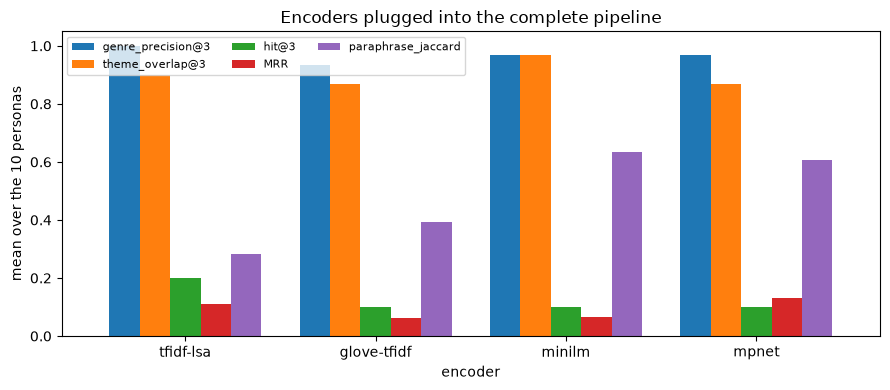

In [31]:
# --- Figure: encoders ------------------------------------------------------------
ax = enc_table[["genre_precision@3", "theme_overlap@3", "hit@3", "MRR", "paraphrase_jaccard"]].plot.bar(
    figsize=(9, 4), width=0.8, rot=0)
ax.set_ylim(0, 1.05); ax.set_ylabel("mean over the 10 personas")
ax.set_title("Encoders plugged into the complete pipeline")
ax.legend(ncol=3, fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "06_encoders.png", dpi=150); plt.show()

## 8. Blind manual judgments (pooling)

Hit@3 and MRR only know the 3 to 6 books we listed in advance. A relevant book we did not think of (for instance *The Little Prince* for the children's fantasy persona) counts as a miss, which penalises systems that propose good but less obvious books.

The standard solution (*pooling*, as in the TREC evaluation campaigns) is to **judge by hand every book that any system put in its top 3**. The file `data/eval/judgments.csv` is **blind**: each row shows the request and one book (title, authors, genres, blurb), never the system that proposed it, and the rows are shuffled within each persona. The judge writes `1` (relevant) or `0` (not relevant) in the `relevant` column. Existing judgments are kept when systems are added (GloVe, MPNet on Colab).

**Judging guideline.** A book is relevant if a reader who wrote this request would be happy to receive it: right kind of book, right audience, and close to the requested themes or atmosphere. It does not have to match every detail. The book the user already said they loved is judged like any other book.

**After judging.** Fill the `relevant` column of `data/eval/judgments.csv`, save it as CSV, then run only the first code cell of this notebook (imports) and the cells of sections 8 and 9: they reload the top 3 of each encoder from `data/eval/results/`, so the whole evaluation does not need to be re-run.

In [3]:
# --- Pool of the top 3 of every system, written blind for manual judgment ------
# `tops` comes from section 7; after a restart it is reloaded from data/eval/results/main_*.csv
if "tops" not in globals():
    tops = ev.load_tops()
pool = ev.build_judgment_pool(tops, personas, books)
todo = ev.n_unjudged(pool)
print(f"{len(pool)} (persona, book) pairs in {ev.JUDGMENTS_PATH.relative_to(ROOT)}; {todo} still to judge")

103 (persona, book) pairs in data/eval/judgments.csv; 103 still to judge


In [4]:
# --- Precision@3 according to the manual judgments ----------------------------
judged = ev.judged_precision(tops)
ev.save_results(judged, "judged_precision")
judged      # NaN / n_unjudged > 0 until judgments.csv is filled in

,judged_precision@3,n_unjudged
system,,
glove-tfidf,NaN,30
minilm,NaN,30
mpnet,NaN,30
tfidf-lsa,NaN,30


## 9. Values for the report

The tables below are the exact values to copy into report section 7 (all CSV files are also saved in `data/eval/results/`). With only 10 personas, one persona more or less moves a mean by 0.1: these are **trends**, not statistically robust measurements.

In [5]:
# Values for the report. After a restart, the tables are reloaded from data/eval/results/.
R = ev.RESULTS_DIR
enc_table = enc_table if "enc_table" in globals() else pd.read_csv(R / "encoders.csv", index_col=0)
abl = abl if "abl" in globals() else pd.read_csv(R / "ablation_minilm.csv", index_col=0)
sens = sens if "sens" in globals() else pd.read_csv(R / "weight_sensitivity_themes.csv", index_col=0)
print("Encoders (7.2):");           display(enc_table)
print("Manual judgments (7.2):");   display(judged)
print("Ablation (7.4):");           display(abl)
print("Weights (7.5):");            display(sens.set_index("W_Themes").T)

Encoders (7.2):


,genre_precision@3,theme_overlap@3,hit@3,MRR,constraints_ok,loved_book_returned,median_seconds,paraphrase_jaccard,setup_seconds
encoder,,,,,,,,,
tfidf-lsa,1.000,0.900,0.2,0.109,10/10,2/10,0.033,0.283,142
glove-tfidf,0.933,0.867,0.1,0.063,10/10,1/10,0.022,0.393,89
minilm,0.967,0.967,0.1,0.065,10/10,0/10,0.048,0.633,0
mpnet,0.967,0.867,0.1,0.130,10/10,2/10,0.200,0.607,40


Manual judgments (7.2):


,judged_precision@3,n_unjudged
system,,
glove-tfidf,NaN,30
minilm,NaN,30
mpnet,NaN,30
tfidf-lsa,NaN,30


Ablation (7.4):


,genre_precision@3,theme_overlap@3,hit@3,MRR,constraints_ok,loved_book_returned,median_seconds
variant,,,,,,,
Blurb only (S_desc),0.800,0.967,0.1,0.123,10/10,0/10,0.043
Coverage only,1.000,0.917,0.2,0.151,10/10,0/10,0.041
Without calibration,1.000,0.917,0.2,0.139,10/10,1/10,0.042
Without 'to avoid' penalty,0.967,0.967,0.0,0.055,10/10,0/10,0.042
Without popularity,0.967,0.917,0.1,0.059,10/10,0/10,0.042
Full formula,0.967,0.967,0.1,0.065,10/10,0/10,0.046


Weights (7.5):


W_Themes,1,2,3,4,5
mean Themes score of top 10,0.7279,0.7512,0.7659,0.7758,0.7815
